# 12. A fixed learned score: local versus global inference

Freeze the score observable at **$\mu=1$, nominal NI** and compare its binned
likelihood with the analytical and learned unbinned curves from notebook 03.
The test is whether a locally informative observable remains adequate near
zero and around the secondary minimum. Agreement away from the anchor is
measured, not assumed.

Use **36 bins**, with **144 bins** as a simple resolution control. Both
stat-only and NI-profiled curves use the same fixed event partition throughout
the entire scan. The physical likelihood keeps the exact $\mu$ and $\sqrt\mu$
coefficients; it is not replaced by a Taylor expansion.

Reuse the completed 04 **10M selected-event bank**, its filtered learned ratios,
and the matching saved unbinned references. No new events, training, interpolation
study or toys are required. This notebook replaces the retired notebook-12
diagnostic study; its old outputs remain untouched.

### Run from the top

Use the same `RUN_NAME`, `MODE`, overrides, Unity bundle and ensemble filter as
03 and the completed 04. The setup downloads a fresh pinned source checkout.
Cached ratios are verified and staged on Colab local disk; histogram filling
and the scalar nuisance fits are CPU work. A CPU Colab runtime is sufficient.
Run 04's final export cell first if its baseline manifest is not present.

In [1]:
import os
import sys
from pathlib import Path

RUN_NAME = "paper-distinct-s-v4"
MODE = os.environ.get("POODEMO_MODE", "production")  # production or smoke
CONFIG_OVERRIDES = {}  # e.g. {"quadrature_per_process": 500_000, "epochs": 150}
JAX_BACKEND = os.environ.get("POODEMO_JAX_BACKEND", "auto")  # auto, gpu, or cpu

SOURCE_COMMIT = "36091e8eb77c8e5fda8654ea161879b99c40ce18"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    requested_backend = JAX_BACKEND.strip().lower()
    if requested_backend not in ("auto", "gpu", "cpu"):
        raise ValueError("JAX_BACKEND must be auto, gpu, or cpu")
    selected_backend = requested_backend
    if requested_backend == "auto":
        try:
            gpu_probe = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                                       capture_output=True, text=True, timeout=10)
            gpu_present = gpu_probe.returncode == 0 and bool(gpu_probe.stdout.strip())
        except (OSError, subprocess.TimeoutExpired):
            gpu_present = False
        selected_backend = "gpu" if gpu_present else "cpu"
    # CUDA-only selection fails visibly if initialization fails. Keep PyTorch's
    # CUDA visibility and avoid JAX reserving most GPU memory before training.
    jax_platform = "cuda" if selected_backend == "gpu" else "cpu"
    os.environ["JAX_PLATFORMS"] = jax_platform
    os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    ROOT = Path(os.environ.get("POODEMO_ROOT", f"/content/drive/MyDrive/poodemo/runs/{RUN_NAME}"))
    import tempfile
    # Download afresh even in a reused runtime; do not alter older checkouts.
    REPO_DIR = Path(tempfile.mkdtemp(prefix="poodemo-12-", dir="/content"))
    print(f"Notebook 12 source: {SOURCE_COMMIT} (fresh download)")
    if not (REPO_DIR / "pyproject.toml").exists():
        import getpass
        import io
        import shutil
        import tarfile
        import urllib.error
        import urllib.request

        archive_url = f"https://api.github.com/repos/rafaellopesdesa/poodemo/tarball/{SOURCE_COMMIT}"

        def fetch_source(token=None):
            headers = {"Accept": "application/vnd.github+json", "User-Agent": "poodemo-colab"}
            if token:
                headers["Authorization"] = "Bearer " + token
            request = urllib.request.Request(archive_url, headers=headers)
            with urllib.request.urlopen(request, timeout=180) as response:
                return response.read()

        try:
            archive_bytes = fetch_source()
        except urllib.error.HTTPError as error:
            if error.code not in (401, 403, 404):
                raise RuntimeError(f"Repository download failed (HTTP {error.code}).") from None
            token = None
            try:
                from google.colab import userdata
                token = userdata.get("GITHUB_TOKEN")
            except Exception:
                pass
            if not token:
                token = getpass.getpass("GitHub token with read access to poodemo: ").strip()
            if not token:
                raise RuntimeError("Provide a GitHub token with read access to download the pinned notebook 12 source.")
            try:
                archive_bytes = fetch_source(token)
            except urllib.error.HTTPError as auth_error:
                raise RuntimeError(f"Repository download failed (HTTP {auth_error.code}); check token access.") from None
            finally:
                token = None

        # Validate archive paths and reject links before extracting the source.
        with tempfile.TemporaryDirectory(prefix="poodemo-source-") as temp:
            staging = Path(temp).resolve()

            def safe_destination(name):
                destination = (staging / name).resolve()
                if not destination.is_relative_to(staging):
                    raise RuntimeError("Unsafe path in source archive.")
                return destination

            with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
                for entry in archive.getmembers():
                    safe_destination(entry.name)
                    if not (entry.isfile() or entry.isdir()):
                        raise RuntimeError("Links and special files are not supported in the source archive.")
                archive.extractall(staging)
            candidates = [p.parent for p in staging.rglob("pyproject.toml") if (p.parent / "poodemo").is_dir()]
            if len(candidates) != 1:
                raise RuntimeError("The downloaded archive must contain one poodemo repository checkout.")
            shutil.copytree(candidates[0], REPO_DIR, dirs_exist_ok=True)
        del archive_bytes

    if os.environ.get("POODEMO_SKIP_INSTALL") != "1":
        from importlib.metadata import version, PackageNotFoundError
        # JAX discovers every installed plugin, even when selecting CPU.
        # Retain already-matched CUDA 12 packages when rerunning GPU setup.
        remove_plugins = []
        for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt", "jax-cuda13-plugin", "jax-cuda13-pjrt"):
            try:
                installed_version = version(package)
            except PackageNotFoundError:
                continue
            if not (selected_backend == "gpu" and package.startswith("jax-cuda12-") and installed_version == "0.5.3"):
                remove_plugins.append(package)
        if remove_plugins:
            subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y", "-q", *remove_plugins])
        gpu_requirements = (["jax==0.5.3", "jaxlib==0.5.3",
                             "jax-cuda12-plugin[with-cuda]==0.5.3", "jax-cuda12-pjrt==0.5.3"]
                            if selected_backend == "gpu" else [])
        # Resolve with the base requirements so PyTorch's CUDA dependencies are
        # considered together with JAX's. Avoid blanket --upgrade changes.
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                               str(REPO_DIR / "requirements-colab.txt"), *gpu_requirements])
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)])

        # Check the live notebook kernel before any expensive network training.
        import jax
        import jaxlib
        import jax.numpy as jnp
        if jax.__version__ != "0.5.3" or jaxlib.__version__ != "0.5.3":
            raise RuntimeError("JAX packages are stale in this kernel. Restart the runtime and rerun setup.")
        if selected_backend == "gpu":
            for package in ("jax-cuda12-plugin", "jax-cuda12-pjrt"):
                if version(package) != "0.5.3":
                    raise RuntimeError(f"{package} must match JAX 0.5.3. Restart the runtime and rerun setup.")
        jax.config.update("jax_platforms", jax_platform)
        jax.config.update("jax_enable_x64", True)
        try:
            jax_devices = jax.devices()
            if not jax_devices or any(device.platform != selected_backend for device in jax_devices):
                raise RuntimeError(f"Expected {selected_backend} devices; found {jax_devices}")
            probe_value, probe_gradient = jax.jit(jax.value_and_grad(lambda x: jnp.sum(x*x)))(
                jnp.asarray([1., 2., 3.], dtype=jnp.float64))
            probe_gradient.block_until_ready()
            if (float(probe_value) != 14. or list(probe_gradient) != [2., 4., 6.]
                    or probe_gradient.dtype != jnp.float64
                    or any(device.platform != selected_backend for device in probe_gradient.devices())):
                raise RuntimeError("JAX double-precision value/gradient check failed")
        except Exception as error:
            raise RuntimeError(
                f"JAX {selected_backend} startup failed. Select a Colab GPU runtime if requesting GPU, "
                "then restart the runtime and rerun setup. Use JAX_BACKEND='cpu' only for an intentional CPU run."
            ) from error
        print(f"JAX {jax.__version__} / jaxlib {jaxlib.__version__}: backend={selected_backend}, {jax_devices}; float64 JIT/gradient OK")

    # A new editable install is not activated in an already-running kernel.
    # Expose the inner package directly, including after a failed import cached
    # the outer /content/poodemo checkout as a namespace package.
    import importlib
    source_root = str(REPO_DIR.resolve())
    if source_root in sys.path:
        sys.path.remove(source_root)
    sys.path.insert(0, source_root)
    importlib.invalidate_caches()
    # Run from the top: subsequent cells recreate objects from this checkout.
    # Clear all poodemo submodules, including old plotting and fit functions.
    for module_name in list(sys.modules):
        if module_name == "poodemo" or module_name.startswith("poodemo."):
            del sys.modules[module_name]

else:
    # Locally: pip install -r requirements-colab.txt && pip install -e .
    ROOT = Path(os.environ.get("POODEMO_ROOT", str(Path.home() / "poodemo-runs" / RUN_NAME)))
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "poodemo" / "pipeline.py").exists():
            sys.path.insert(0, str(candidate))
            break

ROOT.mkdir(parents=True, exist_ok=True)
print(f"Run directory: {ROOT}")
print(f"Mode: {MODE}")

Mounted at /content/drive
Notebook 12 source: 36091e8eb77c8e5fda8654ea161879b99c40ce18 (fresh download)


/tmp/ipykernel_14844/2014164560.py:99: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(staging)


JAX 0.5.3 / jaxlib 0.5.3: backend=gpu, [CudaDevice(id=0)]; float64 JIT/gradient OK
Run directory: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4
Mode: production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from poodemo.pipeline import create_run

run = create_run(ROOT, mode=MODE, overrides=CONFIG_OVERRIDES)
plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True, "grid.alpha": 0.2})
display(pd.Series(run.config, name="configuration"))

,configuration
schema_version,7
mode,production
seed,20261006
physics_overrides,{}
toolkit_commit,fc09848fc6540fd32310faebbe9db6eea7ecd17b
n_per_sample,5000000
ni_sample_multiplier,10
generation_chunk,250000
preselection_train_cap,1000000
ratio_train_cap,2000000


### The score convention and sigmoid

Write $F_j(x)=\nu_jp_j(x)$ for a selected component intensity and use
$$
f(x;\mu)=(\mu-\sqrt\mu)F_S(x)+\sqrt\mu F_{SBI}(x)
+(1-\sqrt\mu)F_B(x)+F_{NI}(x).
$$
The per-event intensity score at nominal NI is
$$
t_1(x)=\left.\partial_\mu\log f(x;\mu)\right|_1
=\frac{1}{2}\frac{1+F_{SBI}/F_S-F_B/F_S}{F_{SBI}/F_S+F_{NI}/F_S}
=\frac{F_S+F_{SBI}-F_B}{2(F_{SBI}+F_{NI})}.
$$
The implementation includes this factor of $1/2$ before centering and applying
the sigmoid, so the observable uses the derivative with respect to $\mu$.
When the component ratios refer to normalized PDFs, their selected rates must
be included. The full extended-likelihood score is
$-\nu'_1+\sum_i t_1(x_i)$, rather than just one event's score.

For the histogram coordinate, retain the earlier centered shape-score convention:
$$
s_1(x)=t_1(x)-\frac{\nu'_1}{\nu_1},\qquad
\nu'_1=\frac{\nu_S+\nu_{SBI}-\nu_B}{2},\qquad
\nu_1=\nu_{SBI}+\nu_{NI},\qquad
z_1(x)=\operatorname{sigmoid}\!\left(\frac{s_1(x)}{0.04}\right).
$$
The constant shift and factor of two preserve event ordering; the sigmoid scale
controls finite-bin resolution. The extended Poisson term retains the count
information. The coordinate, centering and scale never change during a fit.

Evaluate this using only the frozen learned fields
$\widehat F_j/p_S=\nu_j\widehat r_j/Z_j$, with $\widehat r_S=Z_S=1$.
The common $p_S$ cancels. No analytical density defines the observable or
the component bin yields. On the NI up/down samples, evaluate the same nominal
coordinate and then morph the integrated NI templates in the likelihood.

In [3]:
BIN_COUNTS = (36, 144)  # 36 is the baseline; 144 diagnoses bin resolution.
SCORE_SCALE = 0.04      # Earlier centered shape-score convention.
MAX_SELECTED_PER_SOURCE = 10_000_000
MC_ZERO_MAX_BIN = 0.01
MC_ZERO_MAX_TOTAL = 0.05
# These settings identify the completed 04 bank; they do not define the score.
run = run.with_config(reference_ratio_denominator="S", reference_ratio_power=2.0,
    reference_ratio_eta_floor=0.0, mc_zero_max_bin=MC_ZERO_MAX_BIN,
    mc_zero_max_total=MC_ZERO_MAX_TOTAL)

In [4]:
import os
from pathlib import Path
from poodemo.data import save_json
from poodemo.ensemble_bundle import use_bundle, BundleEvaluationRun
from poodemo.member_filter import MemberFilterPolicy, unfiltered_run
from poodemo.practical import (PracticalRun, use_practical_run,
                               reuse_filtered_ensembles as filter_ratio_ensembles)

RATIO_SOURCE = "unity"  # "drive" explicitly selects the original saved models.
UNITY_MODEL_DIR = Path(os.environ.get(
    "POODEMO_UNITY_MODEL_DIR",
    "/content/drive/MyDrive/poodemo/unity_models/paper-distinct-s-v4-unity100",
))
ENSEMBLE_FILTER_POLICY = MemberFilterPolicy(
    catastrophic_peer_factor=100.0,
)  # Match notebook 03, including any custom policy settings.

# Unwrap a previous selection so rerunning this cell never nests evaluations.
source_run = run.base_run if isinstance(run, PracticalRun) else run
source_run = unfiltered_run(source_run)
source_run = source_run.base_run if isinstance(source_run, BundleEvaluationRun) else source_run
if RATIO_SOURCE == "unity":
    if not (UNITY_MODEL_DIR / "bundle.json").is_file():
        raise FileNotFoundError(
            f"Copy the complete Unity model bundle to {UNITY_MODEL_DIR}. "
            "Expected bundle.json, campaign.json and ratios/ directly inside it. "
            "Use the same directory as notebook 03; see unity/README.md.")
    ensemble_run = use_bundle(source_run, UNITY_MODEL_DIR)
elif RATIO_SOURCE == "drive":
    ensemble_run = source_run
else:
    raise ValueError("RATIO_SOURCE must be 'drive' or 'unity'")
run = filter_ratio_ensembles(ensemble_run, policy=ENSEMBLE_FILTER_POLICY)
filter_summary = pd.read_csv(run.path("results", "ensemble_filter", "summary.csv"))
display(filter_summary)
print("Ratio source:", RATIO_SOURCE)
print("Retained ratio models:", run.path("models", "ratios"))
print("Evaluation outputs:", run.evaluation_root)
save_json(run.path("results", "reference_ratio_model_source.json"), {
    "ratio_source": RATIO_SOURCE,
    "bundle_directory": str(ensemble_run.bundle) if RATIO_SOURCE == "unity" else None,
    "campaign_id": ensemble_run.bundle_manifest["campaign_id"] if RATIO_SOURCE == "unity" else None,
    "filter_identity": run.filter_manifest["identity"],
    "filter_policy": run.filter_manifest["inputs"]["policy"],
    "evaluation_root": str(run.evaluation_root),
})

run = use_practical_run(run)
print('Practical evaluation:', run.evaluation_root)

Reusing frozen notebook-03 member selection: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39


,task,original_members,retained_members,rejected_members,status,log_integral,max_point_mass,effective_fraction,log_normalization
0,SBI_over_S,100,100,0,passed,-0.000666,0.000005,0.989804,0.001621
1,B_over_S,100,100,0,passed,-0.000690,0.000005,0.987958,0.001652
2,NI_over_S,100,100,0,passed,-0.005577,0.000014,0.374248,0.007946
3,NI_up_over_NI,100,96,4,passed,0.000110,0.000012,0.412796,0.000183
4,NI_down_over_NI,100,96,4,passed,-0.000133,0.000015,0.340834,-0.000030


Ratio source: unity
Retained ratio models: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/models/ratios
Evaluation outputs: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39
Practical evaluation: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1


In [5]:
from poodemo.signal_reference import load_signal_baseline
from poodemo.signal_benchmarks import load_signal_benchmarks

run, samples = load_signal_baseline(run, 36, max_selected=MAX_SELECTED_PER_SOURCE,
    local_cache=Path('/content/poodemo-12-ratios') if IN_COLAB else None)
references, reference_provenance = load_signal_benchmarks(run)
print('Selected events per source:', samples['target'])
print('Unbinned references:', references.model.unique().tolist())
print(reference_provenance['asimov_note'])

04 ratios verified/staged: S, 10,000,000 events
04 ratios verified/staged: SBI, 10,000,000 events
04 ratios verified/staged: B, 10,000,000 events
04 ratios verified/staged: NI, 10,000,000 events
04 ratios verified/staged: NI_up, 10,000,000 events
04 ratios verified/staged: NI_down, 10,000,000 events
Selected events per source: 10000000
Unbinned references: ['analytic unbinned', 'learned unbinned (analytic Asimov)']
03 learned curve: physical Asimov; binned curves: same-template MC Asimov


### Direct Asimov likelihood scans

Fill each fixed histogram once from all six source banks. Generate Asimov bin
counts at $(\mu_*,\alpha_{NI})=(1,0)$ from these same templates. For each tested
$\mu$, evaluate the full extended Poisson likelihood with NI fixed at zero or
profiled with its existing constraint. The known generating point attains the
nonnegative Asimov objective's global lower bound; conditional NI fits search
all resolved basins and the bounds.

Keep the established total-yield policy: zero a tiny negative total bin mean
only within 0.01 event/bin and 0.05 events in total. Larger deficits and invalid
fits remain visible. The score scan includes $\mu=0$ exactly; saved unbinned
references retain 03's grid and are not extrapolated to zero.

The learned unbinned reference uses 03's physical Asimov construction and its
original normalization, while these binned curves use same-template MC Asimov
counts. Their difference includes finite-MC and modeling effects as well as
compression. The 144-bin control keeps the same score and sample to check how
much of the discrepancy can be explained by coarse binning.

In [6]:
from poodemo.fixed_score import run_fixed_score_study, plot_fixed_score_study

study = run_fixed_score_study(run, samples, benchmarks=references,
    benchmark_provenance=reference_provenance,
    bin_counts=BIN_COUNTS, score_scale=SCORE_SCALE)
display(study['bank']['occupancy'])
display(study['summary'])
display(study['scans'].loc[~study['scans'].valid | study['scans'].alpha_boundary])
print('All score fits valid:', study['metadata']['all_fits_valid'])
print('Results:', study['output'])

Fixed score: S, 10,000,000/10,000,000 events
Fixed score: SBI, 10,000,000/10,000,000 events
Fixed score: B, 10,000,000/10,000,000 events
Fixed score: NI, 10,000,000/10,000,000 events
Fixed score: NI_up, 10,000,000/10,000,000 events
Fixed score: NI_down, 10,000,000/10,000,000 events
Fixed-score fits complete: 36 bins, stat-only and NI profiled
Fixed-score fits complete: 144 bins, stat-only and NI profiled


,source,n_bins,selected,occupied_bins,endpoint_fraction,score_min,score_max,z_min,z_max
0,S,36,10000000,30,2.000000e-07,-0.169946,0.070080,0.014082,0.852206
1,SBI,36,10000000,34,6.000000e-07,-0.232681,0.176705,0.002968,0.988081
2,B,36,10000000,34,2.000000e-07,-0.277602,0.141306,0.000967,0.971603
3,NI,36,10000000,26,0.000000e+00,-0.072977,0.070001,0.138903,0.851955
4,NI_up,36,10000000,26,0.000000e+00,-0.066768,0.069995,0.158532,0.851936
5,NI_down,36,10000000,26,0.000000e+00,-0.069053,0.070036,0.151058,0.852066
6,S,144,10000000,111,0.000000e+00,-0.169946,0.070080,0.014082,0.852206
7,SBI,144,10000000,121,2.000000e-07,-0.232681,0.176705,0.002968,0.988081
8,B,144,10000000,121,1.000000e-07,-0.277602,0.141306,0.000967,0.971603
9,NI,144,10000000,103,0.000000e+00,-0.072977,0.070001,0.138903,0.851955


,n_bins,systematics,points,valid,max_zeroed_total,alpha_boundaries,invalid
0,36,False,84,83,0.000734,0,1
1,36,True,84,83,0.000734,0,1
2,144,False,84,83,0.007872,0,1
3,144,True,84,83,0.007872,0,1


,model,mu,eta,n_bins,systematics,valid,raw_minimum,negative_bins,largest_negative,negative_total,...,q,nll_null,nll_best,truth_certified,alpha_null,alpha_boundary,profile_basins,failed_searches,nfev,message
0,Fixed learned score (36 bins),0.0,1.0,36,False,False,0.0,0.0,0.0,0.0,...,NaN,inf,4.220318e-28,True,0.0,False,0,0,1,NI fixed at zero
1,Fixed learned score (36 bins),0.0,1.0,36,True,False,NaN,NaN,NaN,NaN,...,NaN,NaN,4.220318e-28,True,NaN,False,0,0,19,Conditional profile search failed
168,Fixed learned score (144 bins),0.0,1.0,144,False,False,0.0,0.0,0.0,0.0,...,NaN,inf,3.133736e-27,True,0.0,False,0,0,1,NI fixed at zero
169,Fixed learned score (144 bins),0.0,1.0,144,True,False,NaN,NaN,NaN,NaN,...,NaN,NaN,3.133736e-27,True,NaN,False,0,0,19,Conditional profile search failed


All score fits valid: False
Results: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/results/12_fixed_score/16fd1b46779edac17d94


full


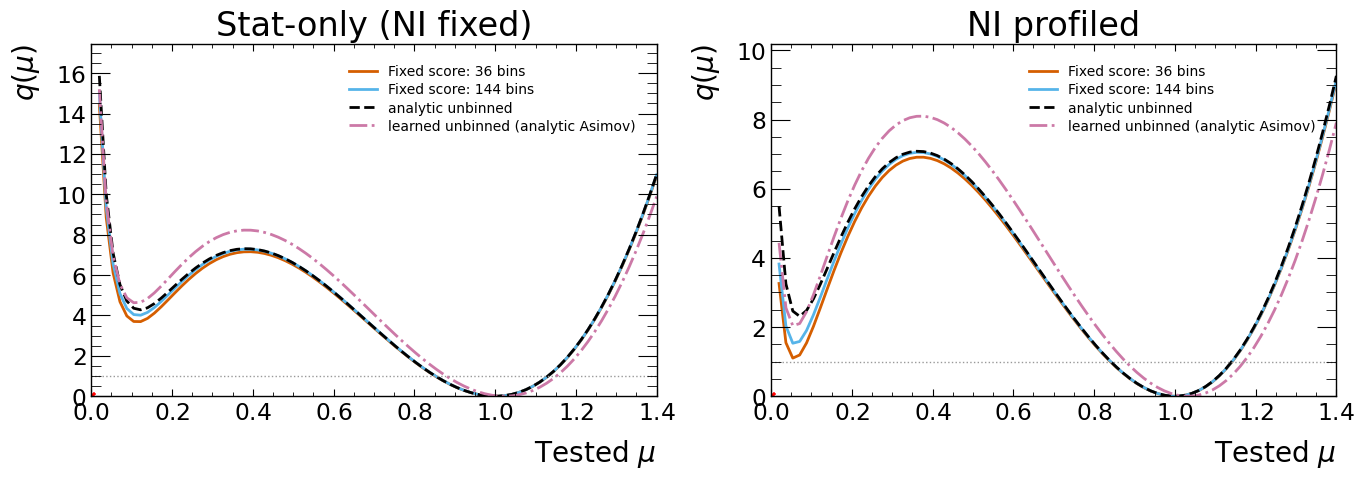

near_one


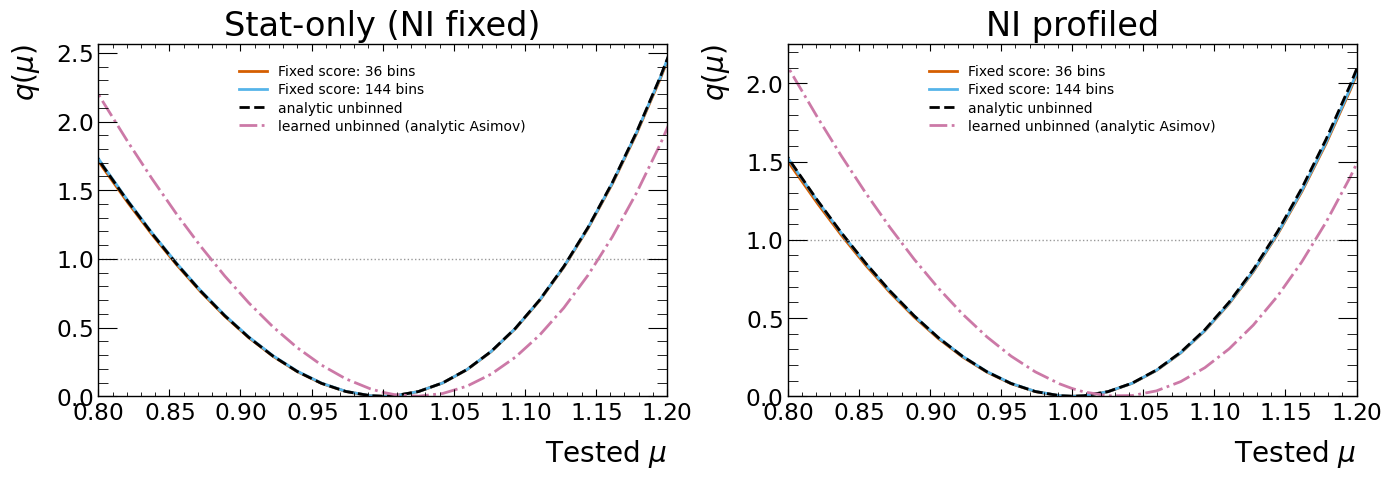

secondary


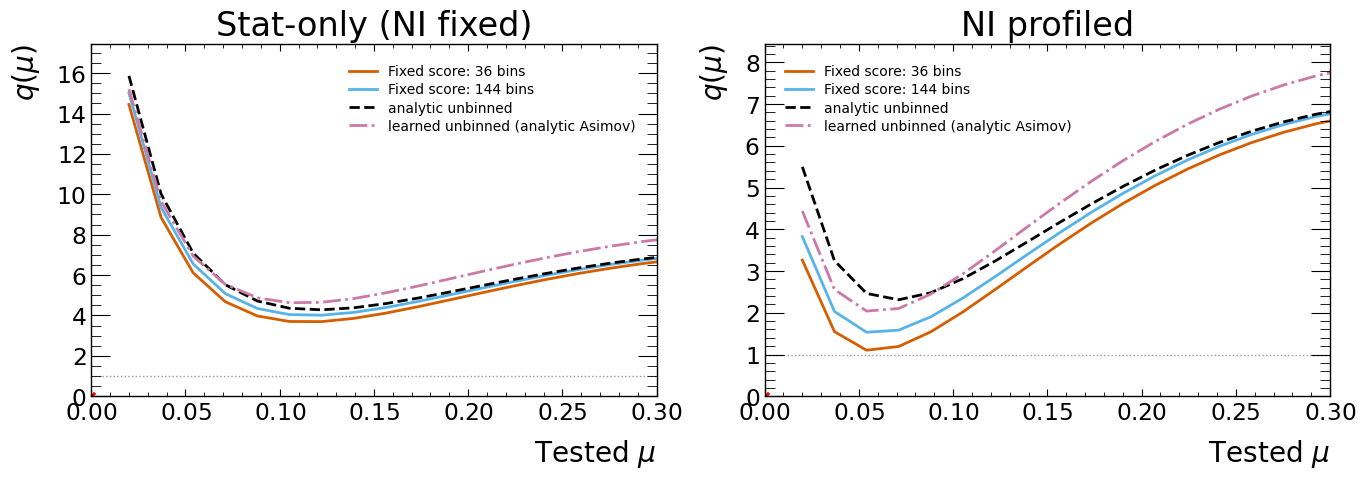

distributions


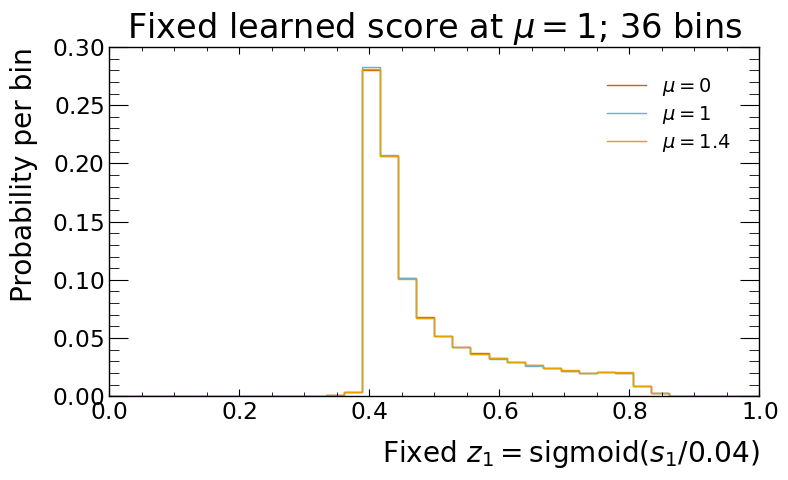

Figures: /content/drive/MyDrive/poodemo/runs/paper-distinct-s-v4/evaluations/paper-distinct-s-v4-unity100/1311f17de040bc40/filtered/a4a9405505b80e39/practical_v1/results/colab_mc/8bfa628d6772d034e1c4/histograms/d9091abb61937f3f3881/inference_581b0fd4c797/plots/12_fixed_score/16fd1b46779edac17d94


In [7]:
FIGURE_DIR = run.path('plots', '12_fixed_score', study['metadata']['identity'][:20])
for name, figure in plot_fixed_score_study(study, FIGURE_DIR).items():
    print(name)
    display(figure)
    plt.close(figure)
print('Figures:', FIGURE_DIR)

### Reading the result

Compare the neighborhood of 1 first, then the low-$\mu$ region and competing
minimum. Similar 36- and 144-bin curves with a persistent unbinned discrepancy
would indicate that simply refining this fixed coordinate is insufficient.
This is an empirical test; local sufficiency does not require global failure
in every model, and a binned score likelihood remains a valid compressed-model
likelihood away from 1 even when it loses information.

For an exact score, local information preservation applies to the parameter
directions represented by the score. A single $\mu$ score at nominal NI need
not retain all information required when NI is profiled; the full local score
vector would include its nuisance direction. Learned-score errors, finite bins,
MC statistics and nuisance morphing after binning are additional approximations.
Thus do not require perfect local profiled closure or universal global optimality.

These are Asimov comparisons, not a coverage or toy-distribution study.
For the local-score argument, see
[Brehmer et al., arXiv:1805.00020](https://arxiv.org/abs/1805.00020).